# Long absence in the wide separate-feature learner

**Question:** does the absent task's RMSE plateau or keep deteriorating over a long absence when capacity is ample?

Setup is the wide separate-feature case from 02d: two teachers with separate lower features, a 90 → 90 learner, both tasks acquired for 1.6M examples in alternating 10k-example blocks. The five acquired checkpoints (weights, Autostep state, normalization means) are reused. Only task 0 then supplies examples for **4M** updates, four times the longest run so far. Target noise standard deviation is 1; the noise floor is RMSE 1.

**Proposed method:** the local backward correction from 02d, switched on at the checkpoint with zero error traces, exactly as in the 1M comparison. Both hidden layers, their normalization means, Autostep state and the active readout learn. The absent readout stays fixed.

**Baseline:** the preserved hidden representation, which freezes hidden weights, biases and normalization state at the checkpoint. Its absent-task RMSE is therefore constant and equals the checkpoint's. Five paired seeds, same inputs and noise, so no uncertainty bands.


In [1]:
import pickle
from pathlib import Path
from common import *

CHECKPOINT = Path('/tmp/two_layer_work/wide_separate_state.pkl')  # (anchor, teachers, keys, final) saved by 02d's wide_retention(shared=False).
if CHECKPOINT.exists():
    anchor, teachers, keys, _ = pickle.load(CHECKPOINT.open('rb'))
else:
    # Reproduce 02d's acquisition: 1.6M examples in alternating 10k-example blocks, five seeds.
    learner, teachers, keys = ready(initialize_wide(False, 5))
    learners, keys, _ = ready(train(repeat(learner, 1), None, teachers, keys[None], 1_600_000, 'all', jnp.array([0])))
    anchor, keys = jax.tree.map(lambda a: a[0], learners), keys[0]
print('Checkpoint RMSE [active, absent]:', np.asarray(evaluate(repeat(anchor, 1), teachers))[0].mean(0))


/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

Checkpoint RMSE [active, absent]: [1.0156876 1.0175235]


In [2]:
def matched_lower_units(anchor, teachers):
    """Learner lower units best matching the absent task's ten true lower features (|firing correlation| on fixed inputs)."""
    x = jax.random.rademacher(jax.random.PRNGKey(926), (4096, INPUTS), dtype=jnp.float32)
    def one(l, t):
        truth = (x @ t[0][1].T > 2).astype(jnp.float32)
        units = (x @ l.weights[0][:, :-1].T + l.weights[0][:, -1] > 0).astype(jnp.float32)
        u, v = truth - truth.mean(0), units - units.mean(0)
        corr = jnp.abs(u.T @ v) / jnp.sqrt((u ** 2).sum(0)[:, None] * (v ** 2).sum(0)[None] + 1e-8)
        return corr.argmax(1)
    return jax.vmap(one)(anchor, teachers)


def long_absence(anchor, teachers, keys, noise=1., steps=4_000_000, every=100_000):
    started = time.perf_counter()
    traces = tuple((jnp.zeros_like(m), jnp.zeros_like(m)) for m in anchor.means)
    units = matched_lower_units(anchor, teachers)
    @jax.jit
    def advance(learners, traces, keys):
        def one(l, tr, key, teacher):
            def sample(carry, _):
                l, tr, key = carry
                key, kx, kn = jax.random.split(key, 3)
                x = jax.random.rademacher(kx, (INPUTS,), dtype=jnp.float32)
                y = target(jax.tree.map(lambda a: a[0], teacher), x) + noise * jax.random.normal(kn, (OUTPUTS,))
                l, tr = local_update(l, tr, x, y)
                return (l, tr, key), None
            return jax.lax.scan(sample, (l, tr, key), None, length=every)[0]
        return jax.vmap(one)(learners, traces, keys, teachers)
    @jax.jit
    def displacement(learners):
        # RMS change of incoming weights (including bias) of the matched absent-task lower units.
        moved = learners.weights[0] - anchor.weights[0]
        return jnp.sqrt(jnp.mean(jax.vmap(lambda m, u: m[u] ** 2)(moved, units), axis=(1, 2)))
    learners, scores, moved = anchor, [], []
    for i in range(steps // every + 1):
        scores.append(np.asarray(ready(evaluate(repeat(learners, 1), teachers)))[0])
        moved.append(np.asarray(displacement(learners)))
        if i < steps // every:
            learners, traces, keys = ready(advance(learners, traces, keys))
    scores, moved = np.asarray(scores), np.asarray(moved)
    assert np.isfinite(scores).all()
    result = dict(scores=scores, moved=moved, every=every, final=learners, seconds=time.perf_counter() - started)
    steps = np.arange(len(scores)) * every
    print('Examples  active   absent   matched-unit weight RMS displacement (mean of 5 seeds)')
    for i in range(0, len(steps), 10):
        print(f"{steps[i]:>9,}  {scores[i, :, 0].mean():.5f}  {scores[i, :, 1].mean():.5f}  {moved[i].mean():.6f}")
    print('Per-seed absent RMSE at 0, 1M, 2M, 3M, 4M:')
    print(np.round(scores[::10, :, 1].T, 4))
    print(f"Runtime: {result['seconds']:.1f}s")
    return result


results = {}
results['noise'] = long_absence(anchor, teachers, keys)


Examples  active   absent   matched-unit weight RMS displacement (mean of 5 seeds)
        0  1.01569  1.01752  0.000000
1,000,000  1.00667  1.02925  0.036151
2,000,000  1.00579  1.03279  0.047199
3,000,000  1.00530  1.04098  0.055629
4,000,000  1.00470  1.05428  0.065637
Per-seed absent RMSE at 0, 1M, 2M, 3M, 4M:
[[1.0222 1.0218 1.0241 1.0182 1.0296]
 [1.0176 1.0243 1.0176 1.0194 1.0211]
 [1.0121 1.0441 1.0463 1.0845 1.0859]
 [1.0131 1.0146 1.0257 1.02   1.0208]
 [1.0227 1.0414 1.0501 1.0628 1.1141]]
Runtime: 104.8s


In [3]:
results['no noise'] = long_absence(anchor, teachers, keys, noise=0.)
Path('results').mkdir(exist_ok=True)
pickle.dump(dict(results=results, anchor=anchor, teachers=teachers), Path('results/wide_separate_4m.pkl').open('wb'))


Examples  active   absent   matched-unit weight RMS displacement (mean of 5 seeds)
        0  1.01569  1.01752  0.000000
1,000,000  1.00241  1.01663  0.008560
2,000,000  1.00101  1.01810  0.010459
3,000,000  1.00355  1.01972  0.011071
4,000,000  1.00058  1.01866  0.011696
Per-seed absent RMSE at 0, 1M, 2M, 3M, 4M:
[[1.0222 1.0185 1.0226 1.022  1.0249]
 [1.0176 1.018  1.0161 1.019  1.0178]
 [1.0121 1.0136 1.0141 1.0185 1.0142]
 [1.0131 1.0105 1.0136 1.0117 1.0112]
 [1.0227 1.0227 1.0241 1.0274 1.0253]]
Runtime: 101.7s


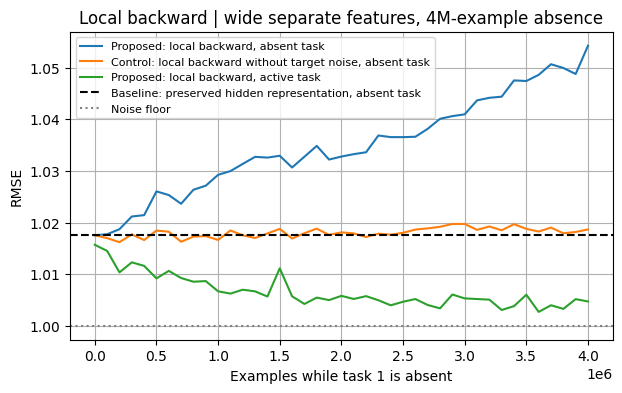

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
steps = np.arange(len(results['noise']['scores'])) * results['noise']['every']
ax.plot(steps, results['noise']['scores'][:, :, 1].mean(1), label='Proposed: local backward, absent task')
ax.plot(steps, results['no noise']['scores'][:, :, 1].mean(1), label='Control: local backward without target noise, absent task')
ax.plot(steps, results['noise']['scores'][:, :, 0].mean(1), label='Proposed: local backward, active task')
ax.axhline(results['noise']['scores'][0, :, 1].mean(), color='black', linestyle='--', label='Baseline: preserved hidden representation, absent task')
ax.axhline(1., color='gray', linestyle=':', label='Noise floor')
ax.set(xlabel='Examples while task 1 is absent', ylabel='RMSE', title='Local backward | wide separate features, 4M-example absence')
ax.grid(); ax.legend(fontsize=8); plt.show()


In [5]:
# Attribute the loss to a layer: combine the checkpoint's and the final learner's layers.
def absent_rmse(lower, upper, teacher):
    l = Learner((lower.weights[0], upper.weights[1], upper.weights[2]), None, (lower.means[0], upper.means[1]), None, None)
    x = jax.random.rademacher(jax.random.PRNGKey(926), (4096, INPUTS), dtype=jnp.float32)
    pred = jax.vmap(lambda a: predict(l, a))(x).reshape(4096, 2, OUTPUTS)[:, 1]
    truth = jax.vmap(lambda a: target(jax.tree.map(lambda b: b[1], teacher), a))(x)
    return jnp.sqrt(1 + jnp.mean((pred - truth) ** 2))

final = results['noise']['final']
table = jax.vmap(lambda a, f, t: jnp.stack([absent_rmse(a, a, t), absent_rmse(a, f, t), absent_rmse(f, a, t), absent_rmse(f, f, t)]))(anchor, final, teachers)
print('Absent-task RMSE per seed after the noisy 4M absence, by (lower layer, upper layer) source:')
print('(checkpoint, checkpoint)  (checkpoint, final)  (final, checkpoint)  (final, final)')
print(np.round(np.asarray(table), 4))


Absent-task RMSE per seed after the noisy 4M absence, by (lower layer, upper layer) source:
(checkpoint, checkpoint)  (checkpoint, final)  (final, checkpoint)  (final, final)
[[1.0222 1.0223 1.029  1.0295]
 [1.0176 1.0174 1.0208 1.0211]
 [1.0122 1.0132 1.0864 1.0859]
 [1.0131 1.0136 1.0195 1.0208]
 [1.0227 1.0235 1.1143 1.1142]]


**Result.** With target noise, absent-task RMSE rises from 1.018 to 1.029 at 1M and 1.054 at 4M examples, and the last million adds the most, so there is no plateau. Two of five seeds carry most of it (1.012 → 1.086 and 1.023 → 1.114); the other three end within 0.01 of where they started. Without target noise the absent task stays between 1.017 and 1.020 for all 4M examples while the active task fits slightly better than with noise.

The matched absent-task lower units' incoming weights move 0.036 RMS by 1M and 0.066 by 4M under noise, close to the √t growth of a random walk; without noise they move 0.009 and 0.012 and are levelling off. Swapping layers between the checkpoint and the final learner places the whole loss in the lower layer: the checkpoint's lower layer with the final upper layer scores like the checkpoint, and the final lower layer with the checkpoint's upper layer scores like the final learner, in every seed.

**Reading.** In this ample-capacity case the persistent degradation is noise-driven diffusion of lower-layer weights that the active task does not constrain, which the upper layer does not compensate for. A random walk has no restoring force, so it cannot plateau, and RMSE accelerates once a drifting unit's hyperplane starts flipping inputs. Continued fitting of the active task on its own causes no measurable loss over 4M examples. Why two seeds are hit much harder is not yet explained. Each 4M run took about 100s.
